In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/milanzdravkovic/pharma-sales-data/salesdaily.csv
/kaggle/input/datasets/milanzdravkovic/pharma-sales-data/saleshourly.csv
/kaggle/input/datasets/milanzdravkovic/pharma-sales-data/salesmonthly.csv
/kaggle/input/datasets/milanzdravkovic/pharma-sales-data/salesweekly.csv


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/input/datasets/milanzdravkovic/pharma-sales-data/salesdaily.csv",
                 parse_dates=["datum"], index_col="datum")
df.head()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
datum,,,,,,,,,,,,
2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [8]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2106 entries, 2014-01-02 to 2019-10-08
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   M01AB         2106 non-null   float64
 1   M01AE         2106 non-null   float64
 2   N02BA         2106 non-null   float64
 3   N02BE         2106 non-null   float64
 4   N05B          2106 non-null   float64
 5   N05C          2106 non-null   float64
 6   R03           2106 non-null   float64
 7   R06           2106 non-null   float64
 8   Year          2106 non-null   int64  
 9   Month         2106 non-null   int64  
 10  Hour          2106 non-null   int64  
 11  Weekday Name  2106 non-null   object 
dtypes: float64(8), int64(3), object(1)
memory usage: 213.9+ KB


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


## Pertanyaan 1: total penjualan per kategori

In [13]:
atc_cols = ["M01AB","M01AE","N02BA","N02BE","N05B","N05C","R03","R06"]

M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
N02BE    63005.402708
N05B     18645.737500
N05C      1249.958333
R03      11608.822917
R06       6107.817500
dtype: float64


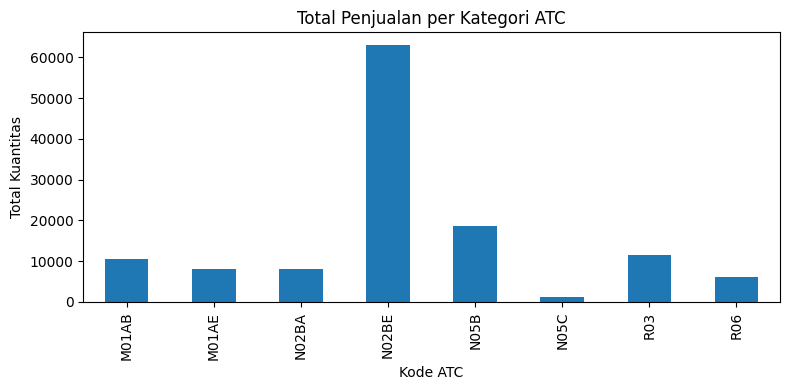

In [14]:
total = df[atc_cols].sum()
print(total)

ax = total.plot(kind="bar", figsize=(8,4))
ax.set_title("Total Penjualan per Kategori ATC")
ax.set_xlabel("Kode ATC")
ax.set_ylabel("Total Kuantitas")
plt.tight_layout()
plt.show()

**Jawaban pertanyaan 1** 

N02BE adalah kategori dengan total penjualan tertinggi, sekitar 63 ribu. Angkanya jauh melampaui yang lain. N02BE sendiri sekitar 3,4 kali lipat N05B yang berada di posisi kedua, dan N05C paling rendah dengan total sekitar 1,2 ribu.

**Kesimpulan**

Kategori N02BE memiliki total penjualan tertinggi, yaitu sekitar 63.005 unit,
jauh di atas kategori lain. Posisi kedua ditempati N05B dengan sekitar 18.646 unit,
disusul R03 dengan sekitar 11.609 unit. Kategori N05C memiliki total penjualan
paling rendah, yaitu sekitar 1.250 unit.

## Pertanyaan 2: penjualan tertinggi

In [15]:
total.sort_values(ascending=False)

N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64

**Jawaban Pertanyaan 2**

Baris paling atas adalah jawabannya: N02BE memiliki penjualan tertinggi.

**Kesimpulan**

Dataset ini hanya memuat kode ATC dan tidak memuat nama merek, sehingga setiap
kode ATC diperlakukan sebagai satu jenis obat. Setelah diurutkan, N02BE berada
di peringkat pertama dengan total penjualan sekitar 63.005 kuantitas, diikuti
N05B (sekitar 18.646) dan R03 (sekitar 11.609). Peringkat terbawah ditempati
N05C dengan sekitar 1.250 kuantitas.

## Pertanyaan 3: tiga terlaris di tiga bulan

In [16]:
for p in ["2015-01", "2016-07", "2017-09"]:
    print("Periode:", p)
    print(df.loc[p, atc_cols].sum().nlargest(3))
    print()

Periode: 2015-01
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

Periode: 2016-07
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

Periode: 2017-09
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64



**Jawaban Pertanyaan 3**

Angka antarbulan tidak sepenuhnya sebanding karena data penjualan setiap bulan tidak punya jumlah hari yang sama dan bisa saja ada hari yang kosong. Untuk pertanyaan ini, yang diminta hanya peringkat tiga teratas per bulan, jadi perbandingan peringkat sudah cukup.

### Pengamatan Pertanyaan 3

| Pengamatan | Penjelasan |
|---|---|
| N02BE dan N05B selalu di dua teratas | Sejalan dengan hasil pertanyaan 1 dan 2, kedua kategori ini konsisten mendominasi pada ketiga periode. |
| Peringkat 3 berubah di Juli 2016 | Pada Januari 2015 dan September 2017 posisi ketiga adalah R03, tetapi pada Juli 2016 digantikan oleh M01AB. |
| Penjualan N02BE paling rendah di Juli 2016 | Totalnya sekitar 652, lebih rendah dibanding September 2017 (sekitar 864) dan Januari 2015 (sekitar 1.044). Perbandingan antarbulan ini hanya gambaran kasar karena jumlah hari dan hari yang kosong bisa berbeda. |


**Kesimpulan**

Pada ketiga periode yang diamati, N02BE dan N05B secara konsisten berada di
peringkat pertama dan kedua. Pada Januari 2015, tiga obat terlaris adalah
N02BE (sekitar 1.044), N05B (sekitar 463), dan R03 (sekitar 177). Pada Juli 2016
urutannya adalah N02BE (sekitar 652), N05B (240), dan M01AB (sekitar 195),
sedangkan pada September 2017 adalah N02BE (sekitar 864), N05B (223), dan R03 (139).
Perbedaan hanya terlihat pada peringkat ketiga, yang berganti dari R03 ke M01AB
pada Juli 2016.

## Pertanyaan 4: paling sering terjual di 2017

In [17]:
hari_terjual = (df.loc["2017", atc_cols] > 0).sum()
print(hari_terjual.sort_values(ascending=False))

# Pembanding: total kuantitas di 2017
print(df.loc["2017", atc_cols].sum().sort_values(ascending=False))

N02BE    361
M01AB    360
M01AE    360
N05B     356
N02BA    350
R06      329
R03      286
N05C      99
dtype: int64
N02BE    9258.804833
N05B     2555.541667
R03      1893.614583
M01AB    1846.617083
M01AE    1387.298333
N02BA    1288.295833
R06       988.860000
N05C      180.333333
dtype: float64


**Jawaban pertanyaan 4**

N02BE adalah obat yang paling sering terjual di 2017, baik diukur dari jumlah hari maupun dari total kuantitas.

### Pengamatan Pertanyaan 4

| Pengamatan | Penjelasan |
|---|---|
| Selisih jumlah hari sangat tipis | N02BE terjual 361 hari, hanya 1 hari lebih banyak dari M01AB dan M01AE (360 hari). Dari sisi frekuensi saja, ketiganya hampir imbang. |
| Total kuantitas memperjelas jawabannya | N02BE mencapai sekitar 9.258, sekitar 3,6 kali N05B di posisi kedua. Kesimpulan N02BE tetap sama, apa pun tafsiran "paling sering" yang dipakai. |
| Urutan berubah antara dua ukuran | M01AB dan M01AE unggul dari R03 dalam jumlah hari, tetapi R03 berada di atas keduanya dalam total kuantitas. R03 terjual lebih jarang, tetapi sekali terjual jumlahnya besar. |
| N05C hanya terjual 99 hari | Sekitar seperempat tahun saja, konsisten dengan temuan sebelumnya bahwa median N05C bernilai 0. |

**Kesimpulan**

Pertanyaan ini dapat ditafsirkan dengan dua cara, yaitu jumlah hari terjadinya
penjualan dan total kuantitas terjual. Berdasarkan jumlah hari, N02BE terjual
pada 361 hari di tahun 2017, hanya selisih satu hari dari M01AB dan M01AE
(360 hari). Berdasarkan total kuantitas, N02BE juga berada di peringkat pertama
dengan sekitar 9.259, jauh di atas N05B (sekitar 2.556). Dengan kedua tafsiran
tersebut, N02BE adalah obat yang paling sering terjual di 2017. Kategori R03
terjual pada lebih sedikit hari (286 hari) tetapi menempati peringkat ketiga
dalam total kuantitas, sedangkan N05C hanya terjual pada 99 hari.

## Pertanyaan 5: rata-rata penjualan harian tertinggi

N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
R06       2.900198
N05C      0.593522
dtype: float64


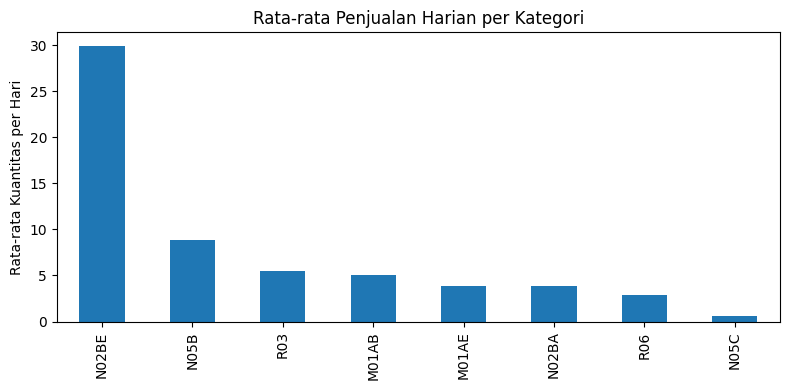

In [18]:
rata = df[atc_cols].mean().sort_values(ascending=False)
print(rata)

ax = rata.plot(kind="bar", figsize=(8,4))
ax.set_title("Rata-rata Penjualan Harian per Kategori")
ax.set_ylabel("Rata-rata Kuantitas per Hari")
plt.tight_layout()
plt.show()

**Jawaban pertanyaan 5**

N02BE memiliki rata-rata penjualan harian tertinggi, sekitar 29,9 per hari.

### Pengamatan Pertanyaan 5

| Pengamatan | Penjelasan |
|---|---|
| N02BE sekitar 3,4 kali N05B | Perbandingannya sama dengan pada total penjualan di pertanyaan 1, karena rata-rata harian adalah total dibagi jumlah hari yang sama untuk semua kategori. |
| Urutan identik dengan pertanyaan 1 dan 2 | Ini wajar. Semua kolom punya 2106 baris, sehingga rata-rata hanyalah total yang diskalakan. |
| M01AE dan N02BA hampir sama | Selisihnya hanya sekitar 0,015 (3,896 dan 3,880), sehingga perbedaan peringkat keduanya sangat tipis. |
| N05C di bawah 1 per hari | Sejalan dengan temuan bahwa N05C hanya terjual di sebagian kecil hari. |

**Kesimpulan**

Kategori N02BE memiliki rata-rata penjualan harian tertinggi, yaitu sekitar 29,9
kuantitas per hari, jauh di atas N05B di peringkat kedua (sekitar 8,9) dan R03
di peringkat ketiga (sekitar 5,5). Kategori N05C memiliki rata-rata terendah,
yaitu sekitar 0,6 per hari. Urutan ini sama dengan urutan total penjualan pada
pertanyaan 1 karena seluruh kategori diamati pada jumlah hari yang sama. M01AE
(sekitar 3,90) dan N02BA (sekitar 3,88) hampir setara sehingga selisih
peringkatnya sangat tipis.

## Pertanyaan 6: pola bulanan obat pernapasan R03

datum
1     6.835980
2     6.896943
3     6.290323
4     5.771528
5     5.006944
6     4.350000
7     2.956989
8     3.102151
9     4.402315
10    7.208589
11    6.226667
12    7.916129
Name: R03, dtype: float64


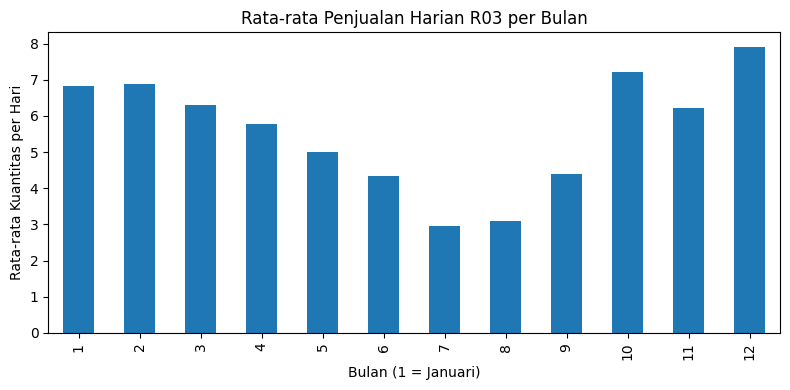

In [19]:
bulanan = df.groupby(df.index.month)["R03"].mean()
print(bulanan)

ax = bulanan.plot(kind="bar", figsize=(8,4))
ax.set_title("Rata-rata Penjualan Harian R03 per Bulan")
ax.set_xlabel("Bulan (1 = Januari)")
ax.set_ylabel("Rata-rata Kuantitas per Hari")
plt.tight_layout()
plt.show()

### Pengamatan Pertanyaan 6

| Pengamatan | Penjelasan |
|---|---|
| Puncak di Desember | Rata-rata penjualan harian R03 tertinggi terjadi pada Desember, yaitu sekitar 7,92 per hari. |
| Titik terendah di Juli | Penjualan terendah terjadi pada Juli, yaitu sekitar 2,96 per hari, disusul Agustus (sekitar 3,10). |
| Selisih mencolok | Rata-rata bulan tertinggi sekitar 2,7 kali bulan terendah, sehingga polanya tidak bisa dianggap kebetulan. |
| Bentuk pola | Penjualan tinggi pada Oktober sampai Maret, menurun bertahap pada April sampai Juli, lalu naik kembali mulai September. |
| Kaitan dengan Pertanyaan 3 | Turunnya R03 dari tiga besar pada Juli 2016 sejalan dengan Juli sebagai bulan penjualan terendah. |

### Kesimpulan Pertanyaan 6

Ya, obat pernapasan R03 lebih banyak terjual pada bulan tertentu. Rata-rata
penjualan harian paling tinggi pada Desember (sekitar 7,92) dan paling rendah
pada Juli (sekitar 2,96). Penjualan cenderung tinggi pada Oktober sampai Maret
dan rendah pada Juni sampai September. Pola ini diduga berkaitan dengan musim,
misalnya meningkatnya gangguan pernapasan pada cuaca dingin, tetapi dataset
tidak memuat informasi lokasi maupun penyebab, sehingga hal tersebut hanya
berupa dugaan dan perlu dibuktikan dengan data tambahan.

## Kesimpulan Umum

| Pertanyaan | Temuan utama |
|---|---|
| 1. Total penjualan per kategori | N02BE tertinggi (sekitar 63.005), N05C terendah (sekitar 1.250) |
| 2. Penjualan tertinggi | N02BE di peringkat pertama. Dataset hanya memuat kode ATC, bukan nama merek |
| 3. Tiga terlaris per periode | N02BE dan N05B selalu di dua teratas. Peringkat ketiga berubah dari R03 ke M01AB pada Juli 2016 |
| 4. Paling sering terjual di 2017 | N02BE, baik dari jumlah hari (361) maupun total kuantitas (sekitar 9.259) |
| 5. Rata-rata penjualan harian | N02BE tertinggi (sekitar 29,9 per hari) |
| 6. Pola bulanan R03 | Tertinggi Desember (sekitar 7,92), terendah Juli (sekitar 2,96), mengindikasikan pola musiman |

Secara keseluruhan, N02BE mendominasi penjualan pada hampir semua ukuran yang
dianalisis. Penjualan R03 menunjukkan pola musiman yang jelas dan dapat
dijadikan dasar untuk perencanaan stok. Analisis ini terbatas pada data harian
yang tersedia, dan penyebab pola musiman perlu diverifikasi dengan data tambahan.